In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 21 - Crime and migration
Police-recorded crime differs across countries in what is counted and how (reporting rates, legal definitions, counting rules), so compare **trends** more than levels; homicide is the most comparable measure. Migration flows are administrative registrations: emigration is under-recorded where people do not deregister (Italy is a known case), so net flows of nationals understate departures. Italy's serious-assault series was dropped because it breaks in 2013-2016.

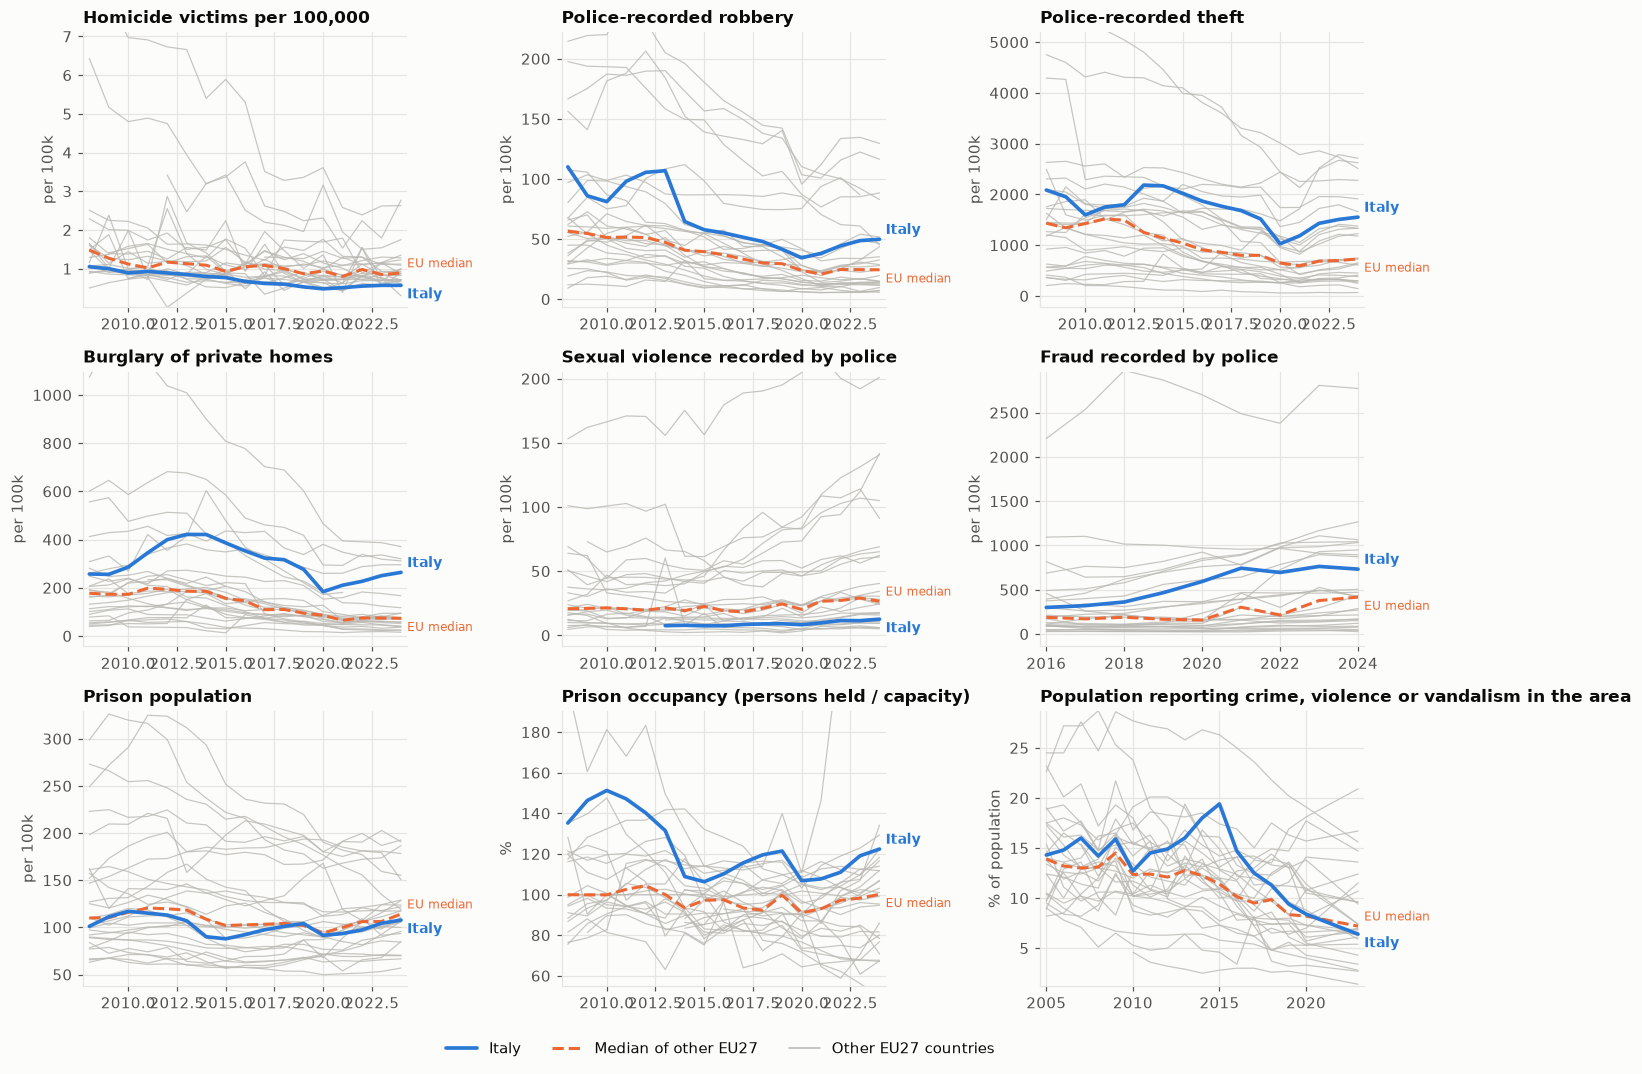

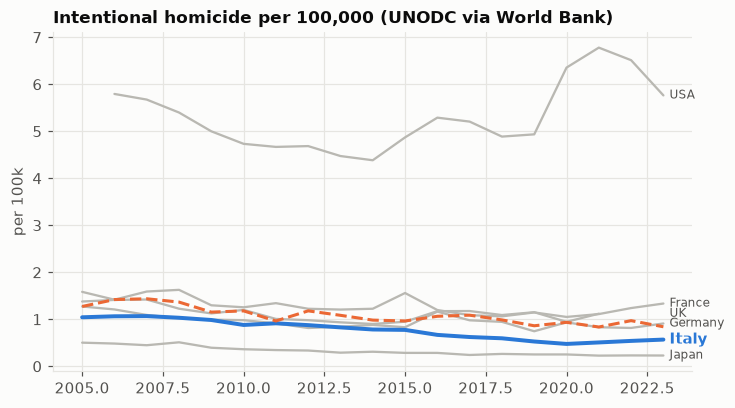

In [2]:
items = [
    (wide(panel, "homicide_victims_per_100k"), "Homicide victims per 100,000", "per 100k"), (wide(panel, "robbery_rate_police"), "Police-recorded robbery", "per 100k"), (wide(panel, "theft_rate_police"), "Police-recorded theft", "per 100k"),
    (wide(panel, "burglary_residential_rate_police"), "Burglary of private homes", "per 100k"), (wide(panel, "sexual_violence_rate_police"), "Sexual violence recorded by police", "per 100k"), (wide(panel, "fraud_rate_police"), "Fraud recorded by police", "per 100k"),
    (wide(panel, "prison_population_per_100k"), "Prison population", "per 100k"), (wide(panel, "prison_occupancy_pct"), "Prison occupancy (persons held / capacity)", "%"), (wide(panel, "crime_perception_pct"), "Population reporting crime, violence or vandalism in the area", "% of population"),
]
small_multiples_wide(items, ncols=3, name="21_crime_overview")
fig, ax = plt.subplots(figsize=(7.5, 4)); w = wide(panel, "wb_homicide_rate")
for c, lab in [("USA", "USA"), ("JPN", "Japan"), ("GBR", "UK"), ("DEU", "Germany"), ("FRA", "France")]:
    ax.plot(w.index, w[c], color=PEER_C, lw=1.5); ax.annotate(lab, (w.index[-1], w[c].dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
ax.plot(w.index, w[ITALY], color=ITALY_C, lw=2.6); ax.annotate("Italy", (w.index[-1], w[ITALY].dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
ax.plot(w.index, eu_median_ex_italy(w), color=EU_C, lw=2, ls="--"); ax.set_title("Intentional homicide per 100,000 (UNODC via World Bank)"); ax.set_ylabel("per 100k"); save(fig, "21_homicide_benchmarks")

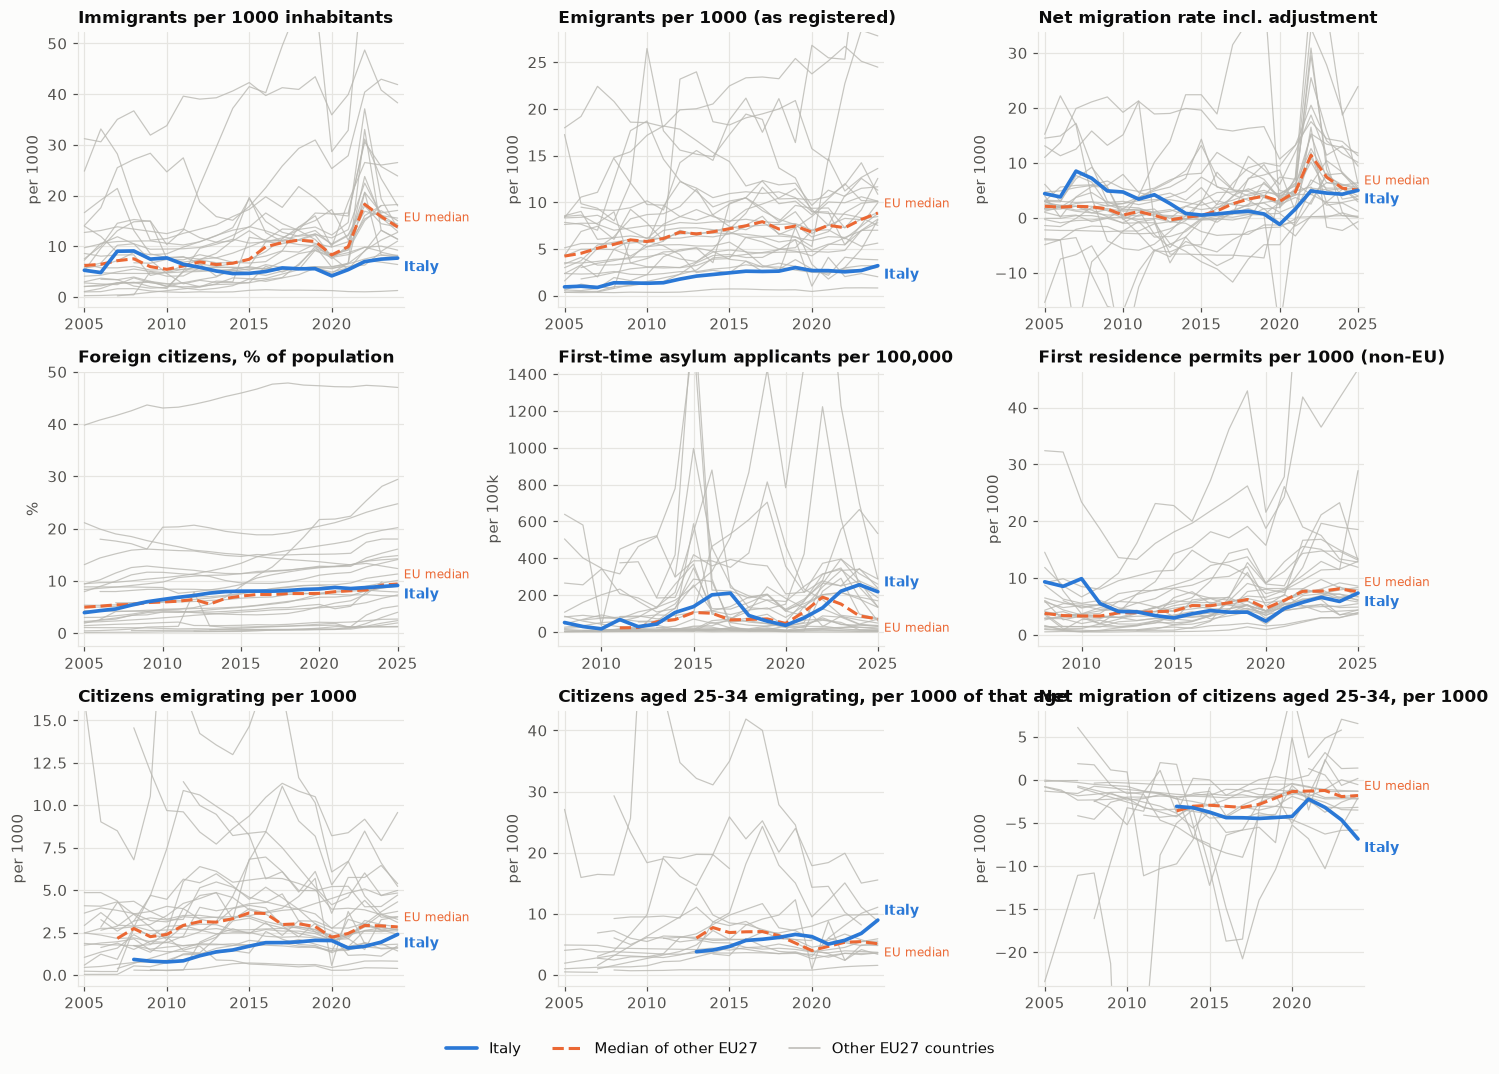

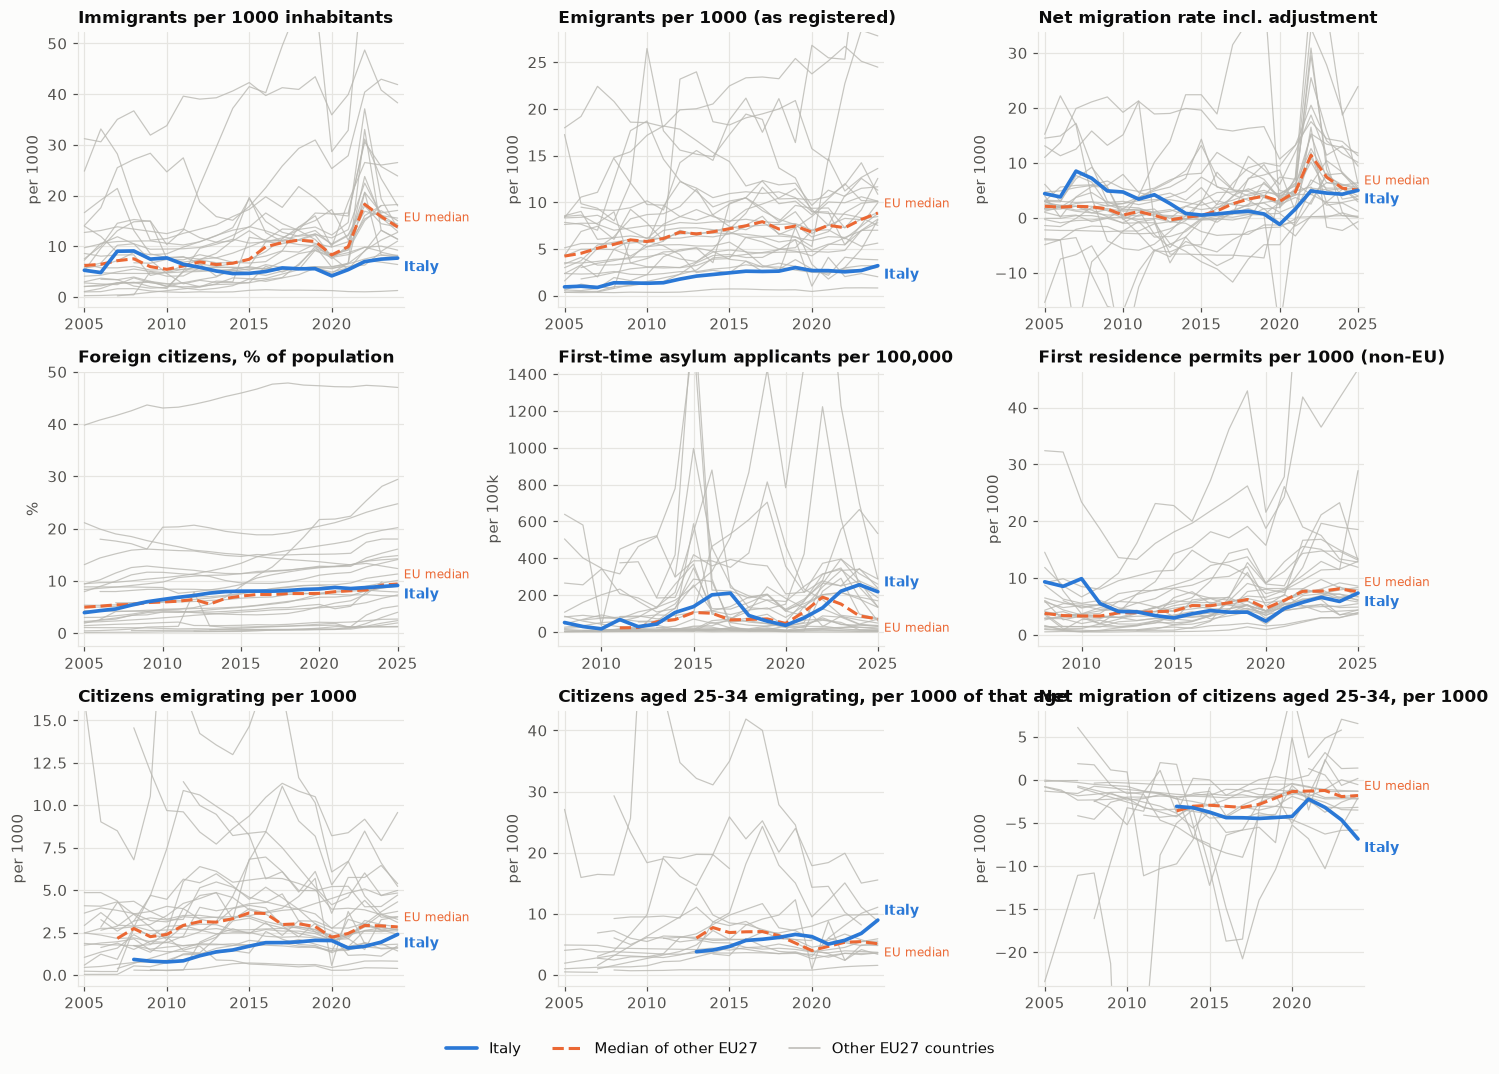

In [3]:
items = [
    (wide(panel, "immigration_per_1000"), "Immigrants per 1000 inhabitants", "per 1000"), (wide(panel, "emigration_per_1000"), "Emigrants per 1000 (as registered)", "per 1000"), (wide(panel, "net_migration_rate_per_1000"), "Net migration rate incl. adjustment", "per 1000"),
    (wide(panel, "foreign_citizens_share_pct"), "Foreign citizens, % of population", "%"), (wide(panel, "asylum_first_applicants_per_100k"), "First-time asylum applicants per 100,000", "per 100k"), (wide(panel, "first_permits_per_1000"), "First residence permits per 1000 (non-EU)", "per 1000"),
    (wide(panel, "emigration_nationals_per_1000"), "Citizens emigrating per 1000", "per 1000"), (wide(panel, "emigration_nationals_25_34_per_1000"), "Citizens aged 25-34 emigrating, per 1000 of that age", "per 1000"), (wide(panel, "net_migration_nationals_25_34_per_1000"), "Net migration of citizens aged 25-34, per 1000", "per 1000"),
]
small_multiples_wide(items, ncols=3, name="21_migration_overview")

In [4]:
names = ["homicide_victims_per_100k", "robbery_rate_police", "theft_rate_police", "burglary_residential_rate_police", "sexual_violence_rate_police", "fraud_rate_police", "prison_population_per_100k", "prison_occupancy_pct", "crime_perception_pct",
         "immigration_per_1000", "emigration_per_1000", "net_migration_rate_per_1000", "foreign_citizens_share_pct", "asylum_first_applicants_per_100k", "first_permits_per_1000", "emigration_nationals_per_1000", "emigration_nationals_25_34_per_1000", "net_migration_nationals_25_34_per_1000"]
rows = {}
for n in names:
    w = wide(panel, n); y = min(int(w[ITALY].dropna().index.max()), 2024)
    rows[n] = {"year": y, "Italy": round(w.loc[y, ITALY], 2), "median others": round(eu_median_ex_italy(w).loc[y], 2), "rank (1=highest)": "%d/%d" % italy_rank(w, y), "Italy first year": int(w[ITALY].dropna().index.min()), "Italy first value": round(w[ITALY].dropna().iloc[0], 2)}
display(pd.DataFrame(rows).T)

,year,Italy,median others,rank (1=highest),Italy first year,Italy first value
homicide_victims_per_100k,2024,0.57,0.89,23/24,2008,1.05
robbery_rate_police,2024,49.77,24.39,6/26,2008,110.03
theft_rate_police,2024,1552.26,726.7,7/27,2008,2085.33
burglary_residential_rate_police,2024,263.84,73.27,5/23,2008,257.04
sexual_violence_rate_police,2024,12.59,26.56,20/27,2013,7.52
fraud_rate_police,2024,732.67,416.55,9/26,2016,300.18
prison_population_per_100k,2024,107.72,114.08,15/27,2008,101.08
prison_occupancy_pct,2024,122.39,100.08,5/27,2008,135.22
crime_perception_pct,2023,6.4,7.2,18/27,2005,14.3
immigration_per_1000,2024,7.66,13.79,24/26,2005,5.25


## Takeaways (Eurostat; UNODC via World Bank for homicide; 2024 unless stated)
- **Violent crime is low and falling; property crime is high.** Homicide victims fell from 1.05 to 0.57 per 100,000 between 2008 and 2024 (median of the other members 0.89; 23rd of 24 countries, i.e. among the lowest). Police-recorded robbery fell from 110 to 50 per 100,000 but is still twice the median (24; 6th highest); theft is 1,552 vs 727 (7th highest) and burglary of private homes 264 vs 73 (5th of 23; it peaked near 400 in 2012). Recorded fraud has more than doubled since 2016 (300 to 733 vs a median of 417), consistent with online fraud being recorded.
- **Recording differs by country:** recorded sexual violence (12.6 per 100,000 vs a median of 26.6) and drug offences are low partly because of reporting and legal definitions; Italy's serious-assault series breaks between 2012 and 2016 and was dropped.
- **Prisons are crowded:** 108 prisoners per 100,000 (median 114) but occupancy of 122% of official capacity (median 100%; 5th highest; 135% in 2008). The share of people reporting crime or vandalism in their area fell from 14.3% (2005) to 6.4% (2023; median 7.2%).
- **Migration is lower than in most EU countries, except for asylum.** Registered immigration is 7.7 per 1000 inhabitants (median 13.8; 24th of 26), foreign citizens are 8.9% of the population (median 9.2%; 3.9% in 2005), first residence permits 5.9 per 1000 (median 8.1). First-time asylum applicants are 256 per 100,000 (median 87; 9th), up from 51 in 2008.
- **The departure of young Italians is visible in Eurostat data.** Italian citizens aged 25-34 emigrating: 9.0 per 1000 of that age group (median 5.1; 4th highest of 15 countries that report it; 3.8 in 2013). Net migration of citizens aged 25-34 (departures minus returns) is -6.9 per 1000, the lowest of the 15 (median -1.8; -3.1 in 2013). Registered emigration is probably under-counted, so these are lower bounds; the data do not show education, but they are consistent with the brain-drain reports cited in the literature notes (docs/literature).